# CellCharter Benchmarking

- Creator: Sebastian Birk (<sebastian.birk@helmholtz-munich.de>)
- Date of Creation: 11.03.2024
- Date of Last Modification: 05.04.2026 (Sebastian Birk; <sebastian.birk@helmholtz-munich.de>)

- Run this notebook in the cellcharter environment, installable from ```../../envs/cellcharter.sh```
- The CellCharter source code is available at https://github.com/CSOgroup/cellcharter.
- The corresponding publication is "Varrone, M., Tavernari, D., Santamaria-Martínez, A., Walsh, L. A. & Ciriello, G. CellCharter reveals spatial cell niches associated with tissue remodeling and cell plasticity. Nat. Genet. 56, 74–84 (2024)".
- The workflow of this notebook follows the tutorial from https://cellcharter.readthedocs.io/en/latest/notebooks/cosmx_human_nsclc.html.

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [22]:
import warnings
import os

import anndata as ad
import squidpy as sq
import cellcharter as cc
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import scvi
import sklearn.metrics as skm
import numpy as np
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from lightning.pytorch import seed_everything
from matplotlib import gridspec
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from analysis_utils import *

seed_everything(12345)
scvi.settings.seed = 12345

Seed set to 12345
Seed set to 12345


### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [31]:
method = 'cellcharter'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# Cellcharter params
emb_key = 'X_cellcharter'

# Cluster params
latent_leiden_resolution = 0.7

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [7]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

/tmp/ipykernel_3603058/3043166597.py:3: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(


In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

### 1.5 Define Functions

In [11]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [12]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

In [23]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs: int | None,
                             radius: float | None,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs: int | None = None,
                             radius: float | None = None,
                             delaunay: bool = True,
                             include_self_loop: bool = False,
                             batch_key: str | None = None,
                             compute_neighbor_counts: bool = False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. Analysis

### 2.1 Retrieve Embeddings

In [14]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_3603058/3735239799.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [15]:
adata.layers["counts"] = adata.X.copy()

#sc.pp.filter_genes(adata, min_counts=3)
#sc.pp.filter_cells(adata, min_counts=3)

sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)

In [16]:
scvi.model.SCVI.setup_anndata(
    adata, 
    layer="counts", 
    batch_key=batch_key,
)

model = scvi.model.SCVI(adata)

In [17]:
model.train(early_stopping=True, enable_progress_bar=True)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA L40S') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/93 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=93` reached.


In [18]:
adata.obsm['X_scVI'] = model.get_latent_representation(adata).astype(np.float32)

In [20]:
adata.obs[batch_key] = adata.obs[batch_key].astype('category')

In [21]:
#adata.obsm['spatial_fov'] = adata.obsm['spatial']
#sq.gr.spatial_neighbors(adata, library_key=batch_key, coord_type='generic', delaunay=True, spatial_key='spatial_fov', percentile=99)

INFO     Creating graph using `generic` coordinates and `None` transform and `2` libraries.                        


In [24]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    batch_key=batch_key,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

Computing spatial neighborhood...

Processing batch harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes....
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


/tmp/ipykernel_3603058/1350574126.py:101: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index



Processing batch harmonised_starmap_plus_mouse_cns_batch15_shared_genes....
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data
/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


In [25]:
cc.gr.aggregate_neighbors(adata, n_layers=3, use_rep='X_scVI', out_key='X_cellcharter', sample_key='sample')

  0%|          | 0/4 [00:00<?, ?it/s]

In [26]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

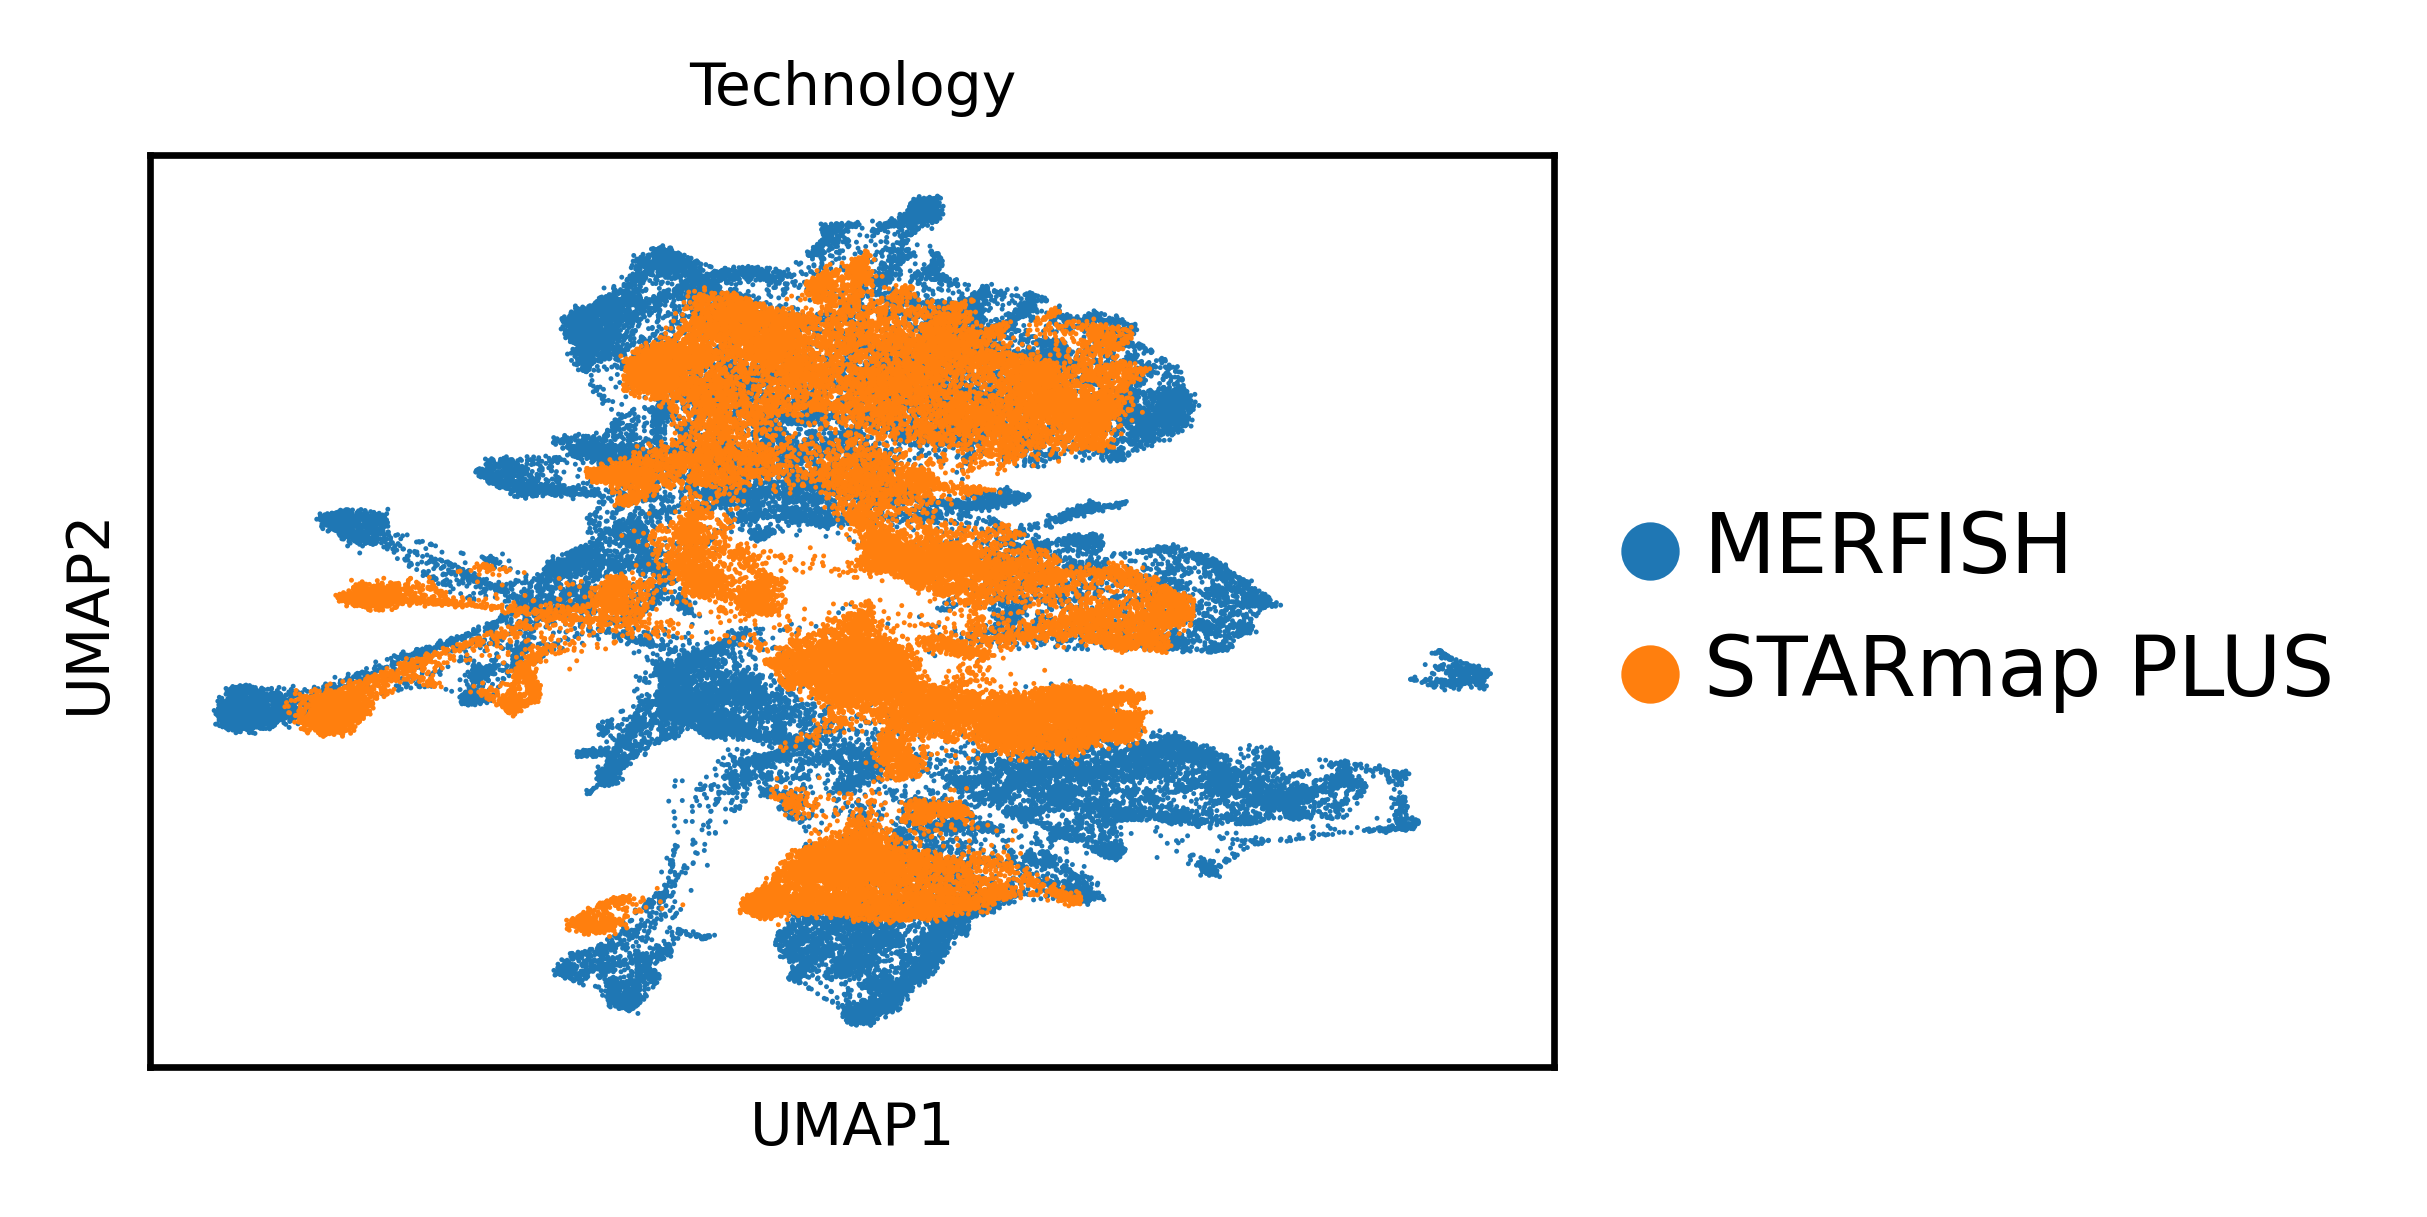

/tmp/ipykernel_3603058/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


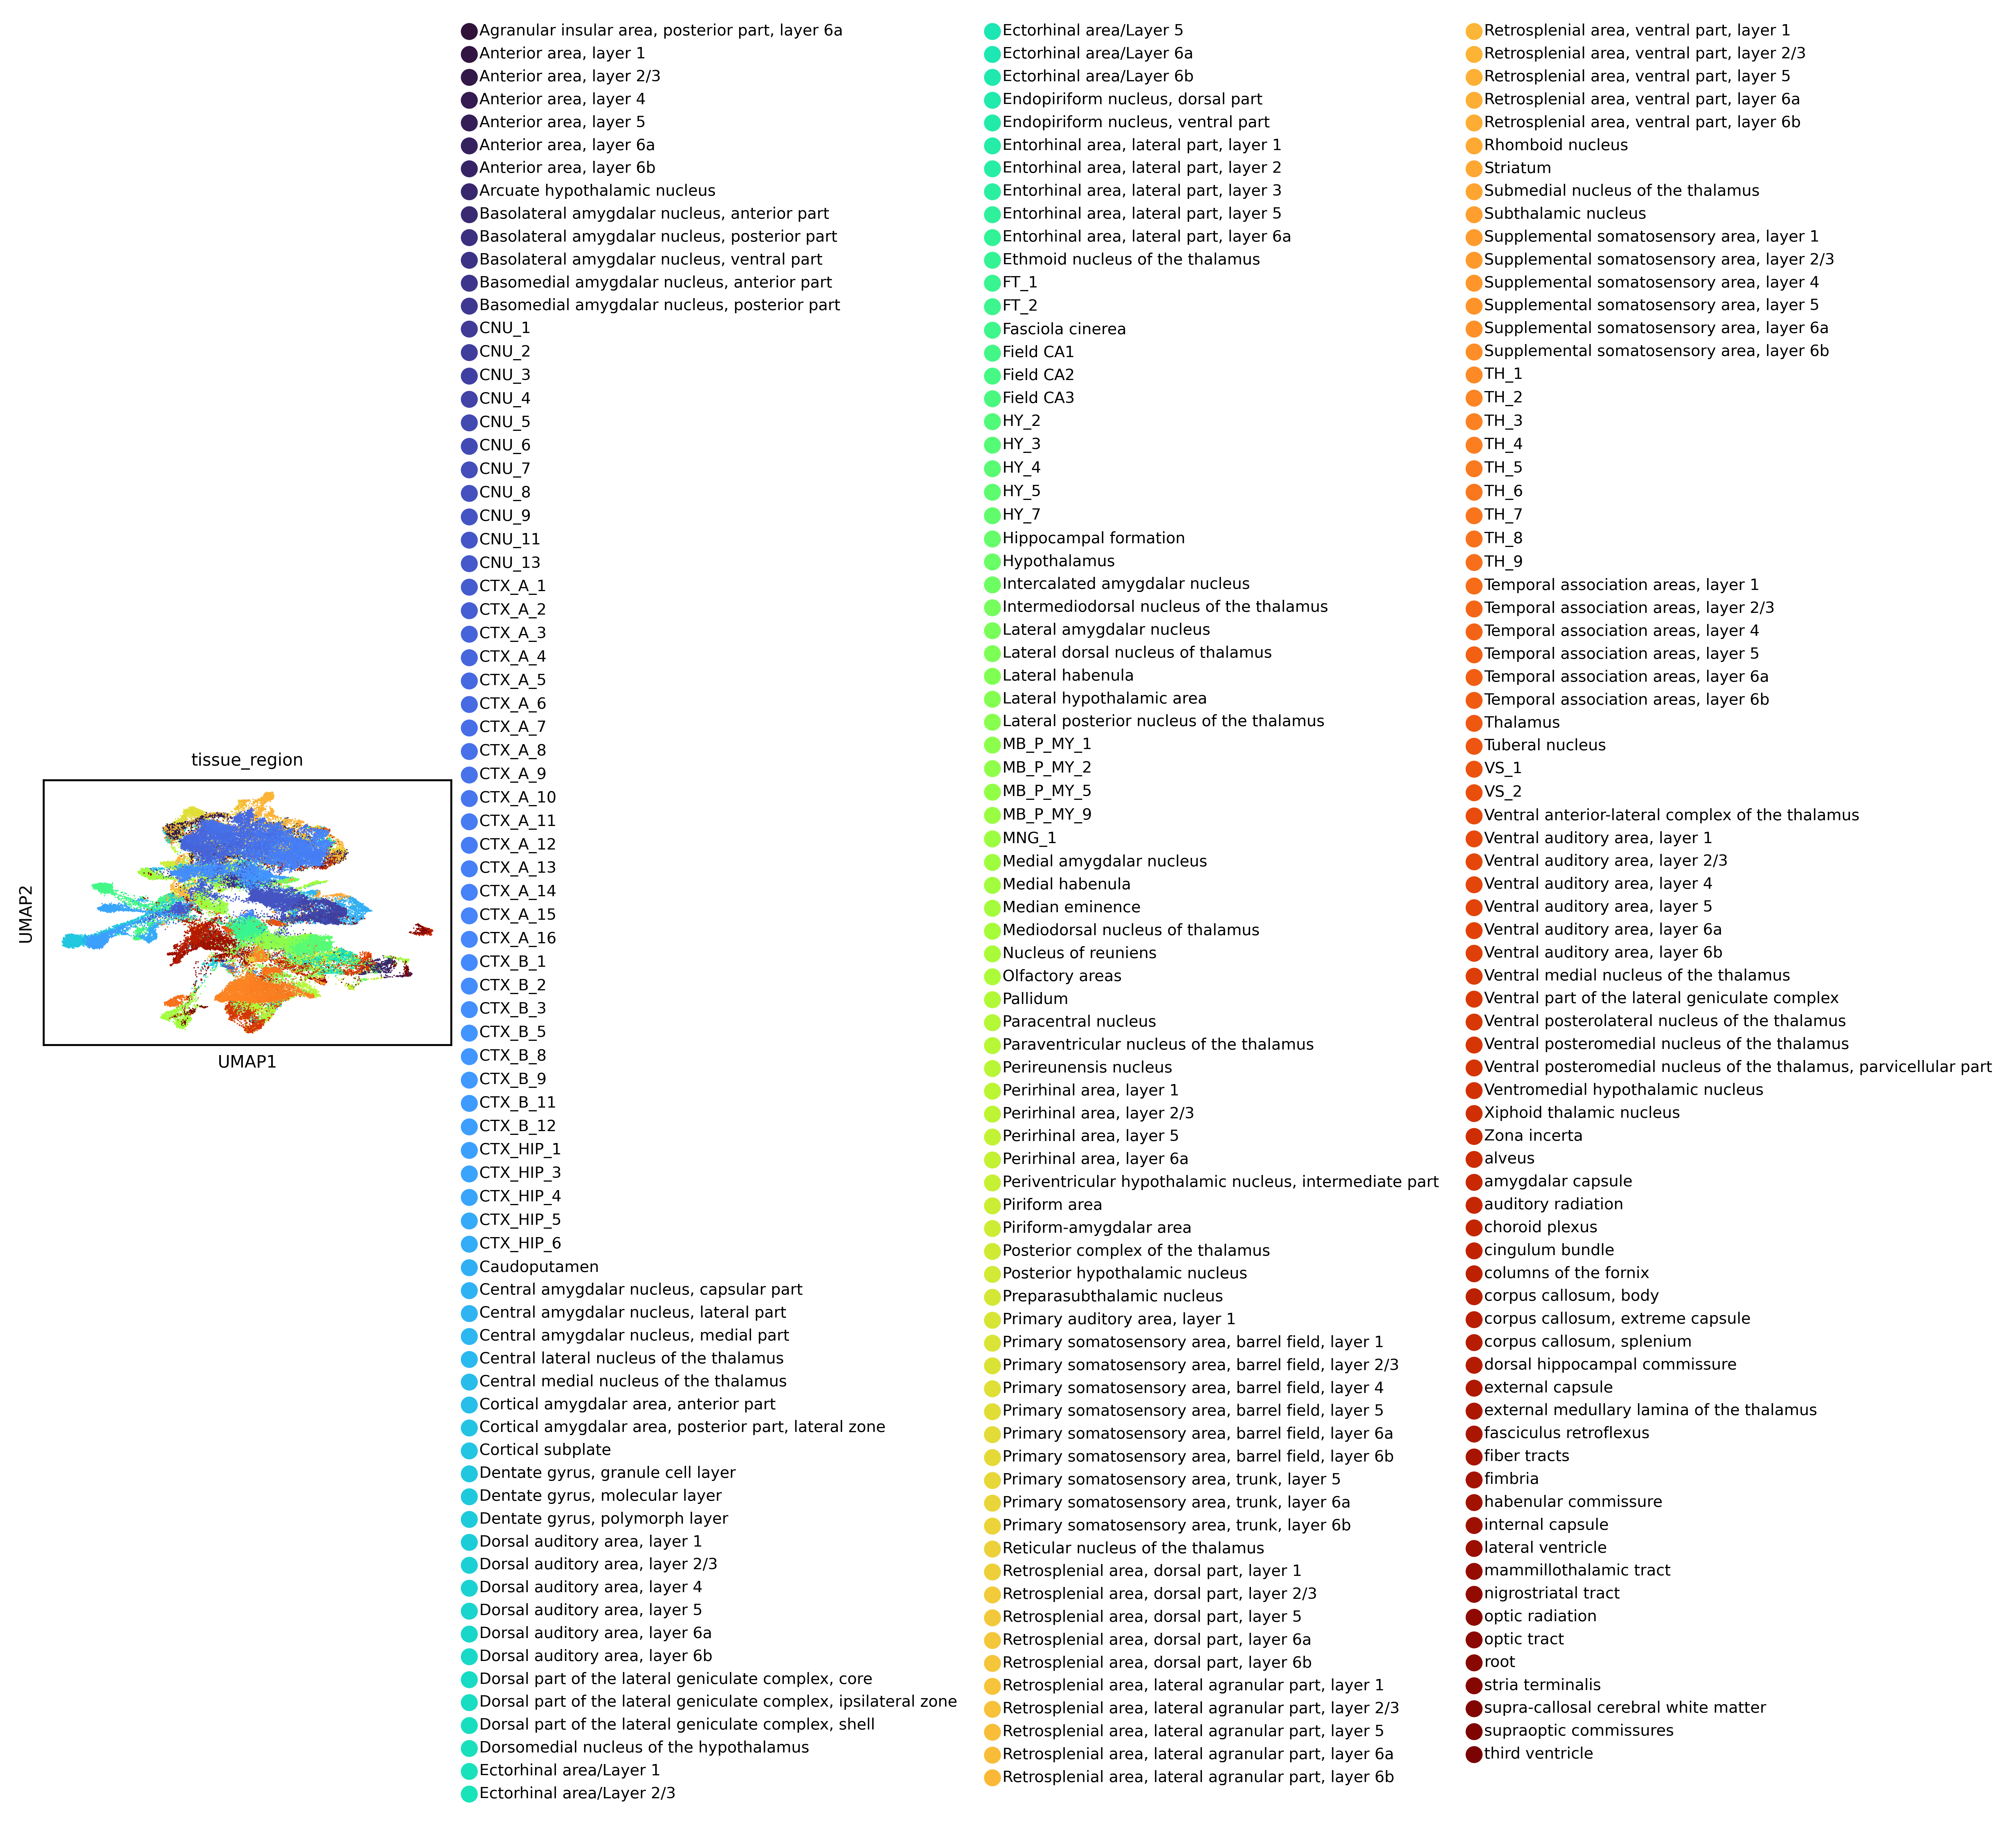

In [27]:
try:
    rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                     n_pcs=n_pcs, key_added=emb_key)
    rsc.tl.umap(adata, neighbors_key=emb_key)
except NameError:
    sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                    n_pcs=n_pcs, key_added=emb_key)
    sc.tl.umap(adata, neighbors_key=emb_key)

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [28]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [38]:
### Plot embedding-based clusters
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

try:
    rsc.tl.leiden(adata,
                  neighbors_key=emb_key,
                  key_added=latent_cluster_key,
                  resolution=latent_leiden_resolution,
                  flavor="igraph",
                  n_iterations=2)
except NameError:
    sc.tl.leiden(adata,
                 neighbors_key=emb_key,
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution,
                 flavor="igraph",
                 n_iterations=2)

In [39]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
X_cellcharter_clusters_res_0.7
14    8568
22    7224
6     6153
20    4940
11    4773
10    4764
15    4724
23    4282
8     3832
1     3380
16    3287
5     3254
13    3131
21    3128
4     2661
0     2456
7     2430
26    2353
3     2060
17    1355
25     999
12     993
24     966
9      880
29     793
18     735
19     648
27     353
2      322
28     260
Name: count, dtype: int64


/tmp/ipykernel_3603058/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


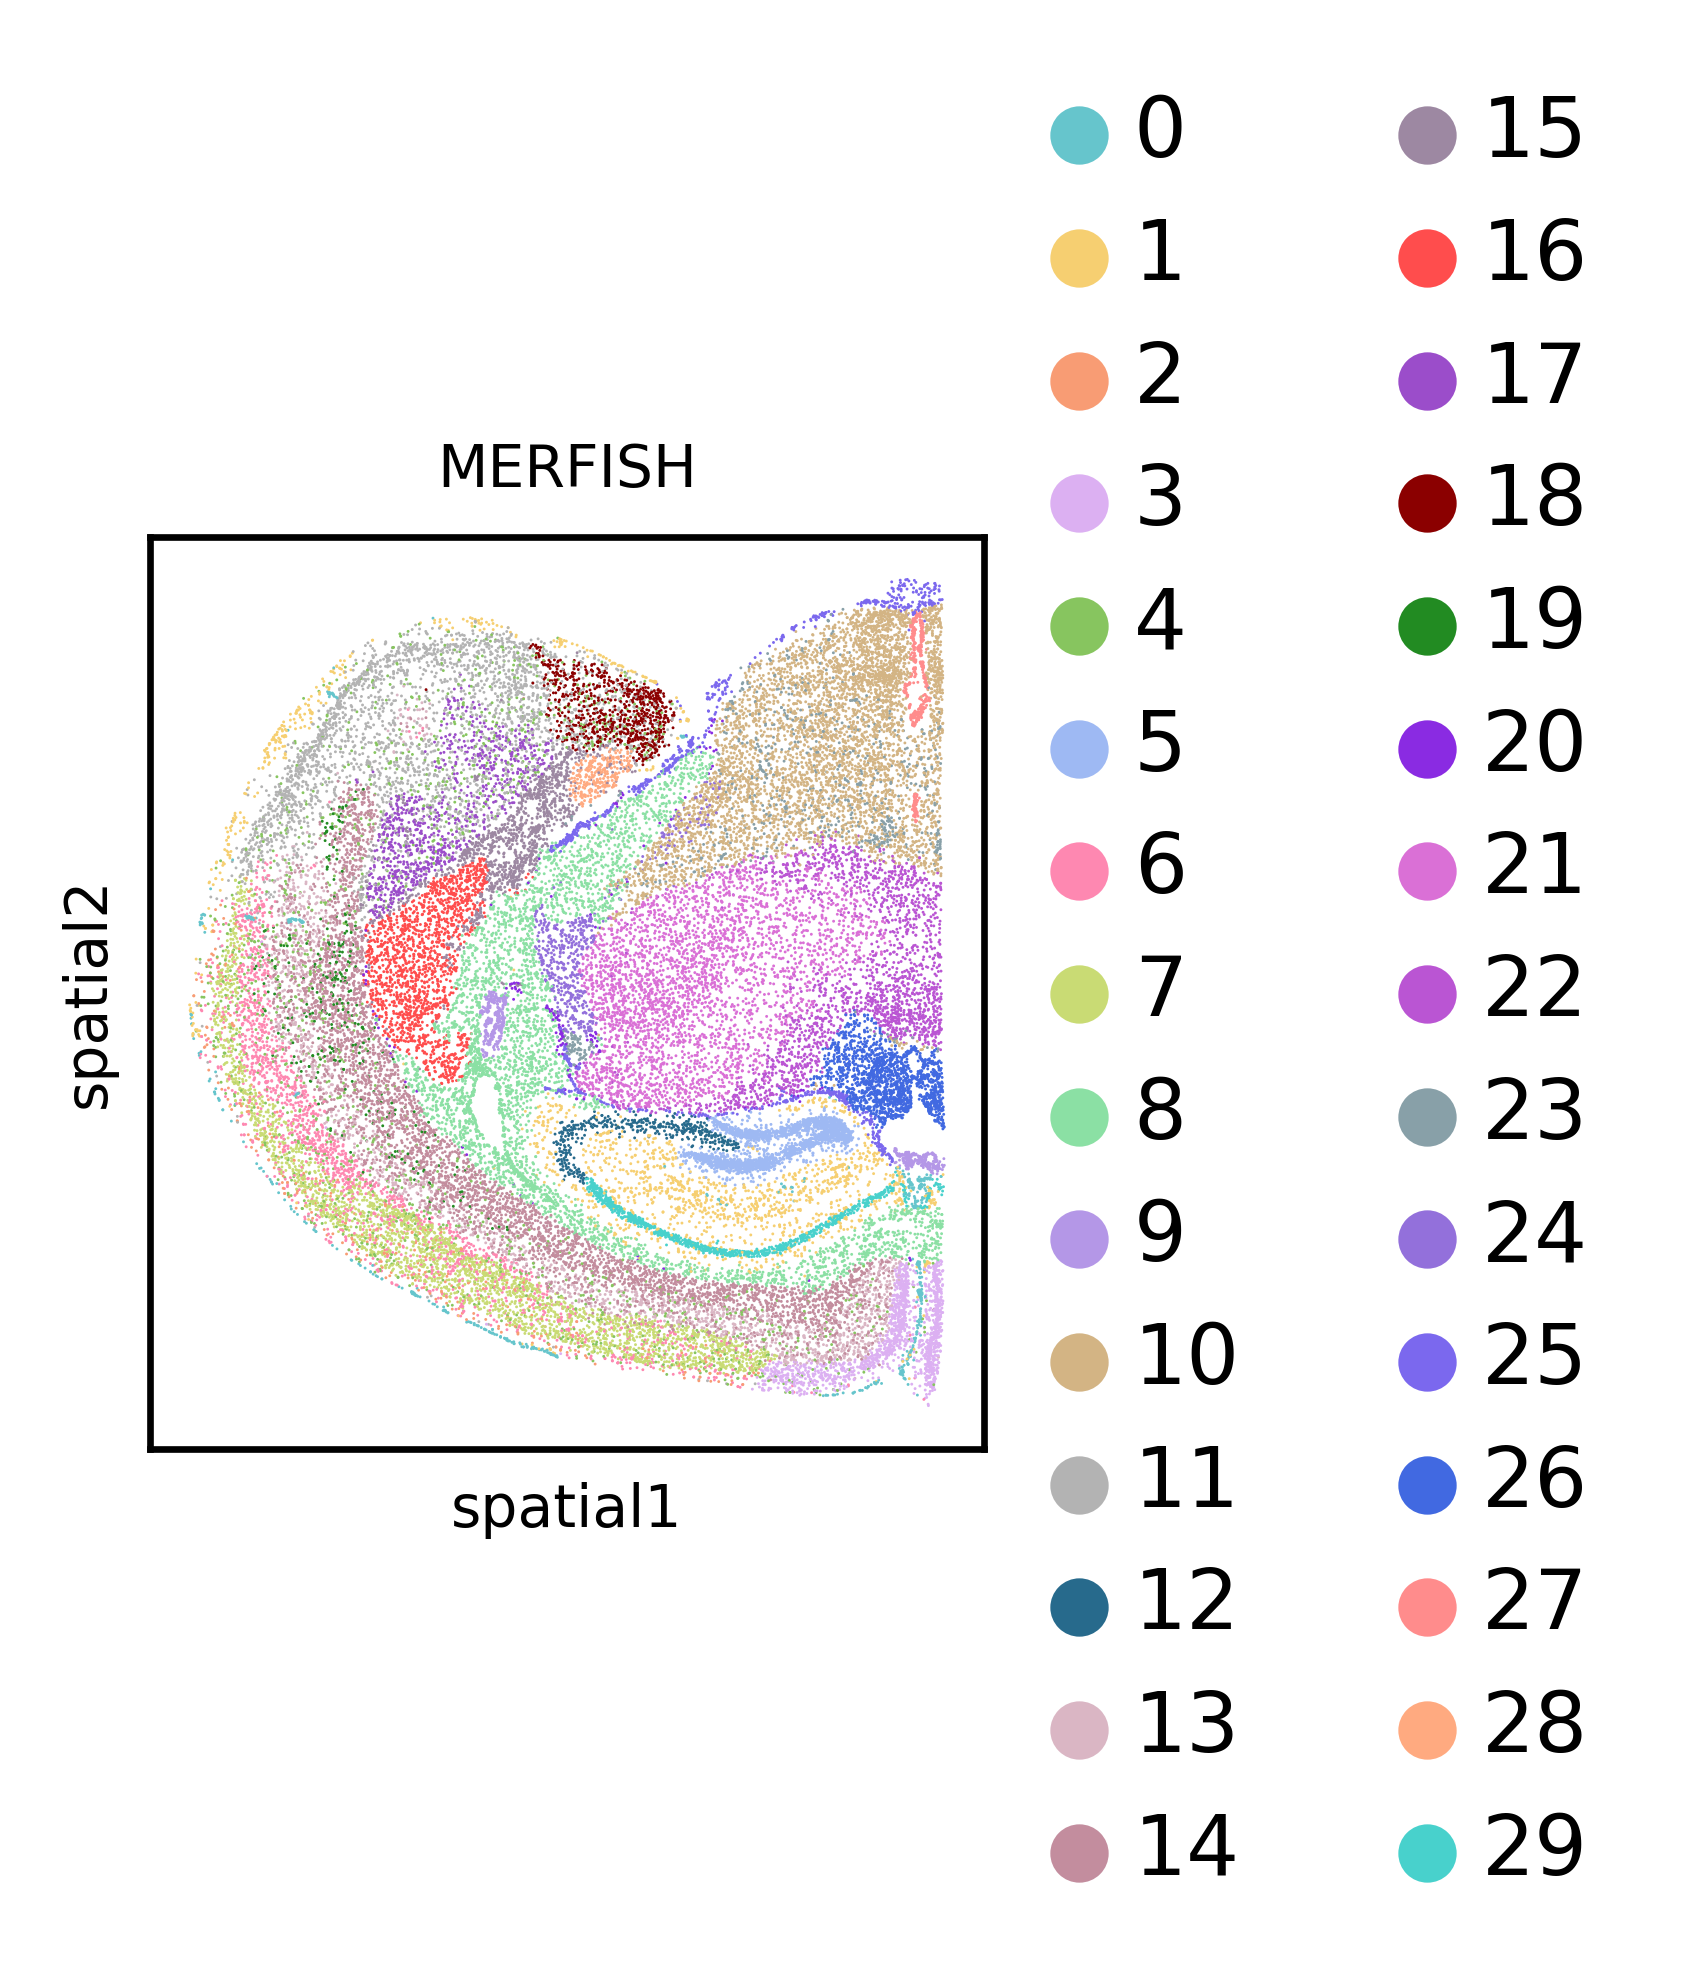

/tmp/ipykernel_3603058/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/cellcharter/lib/python3.12/site-packages/scanpy/plotting/_utils.py:507: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


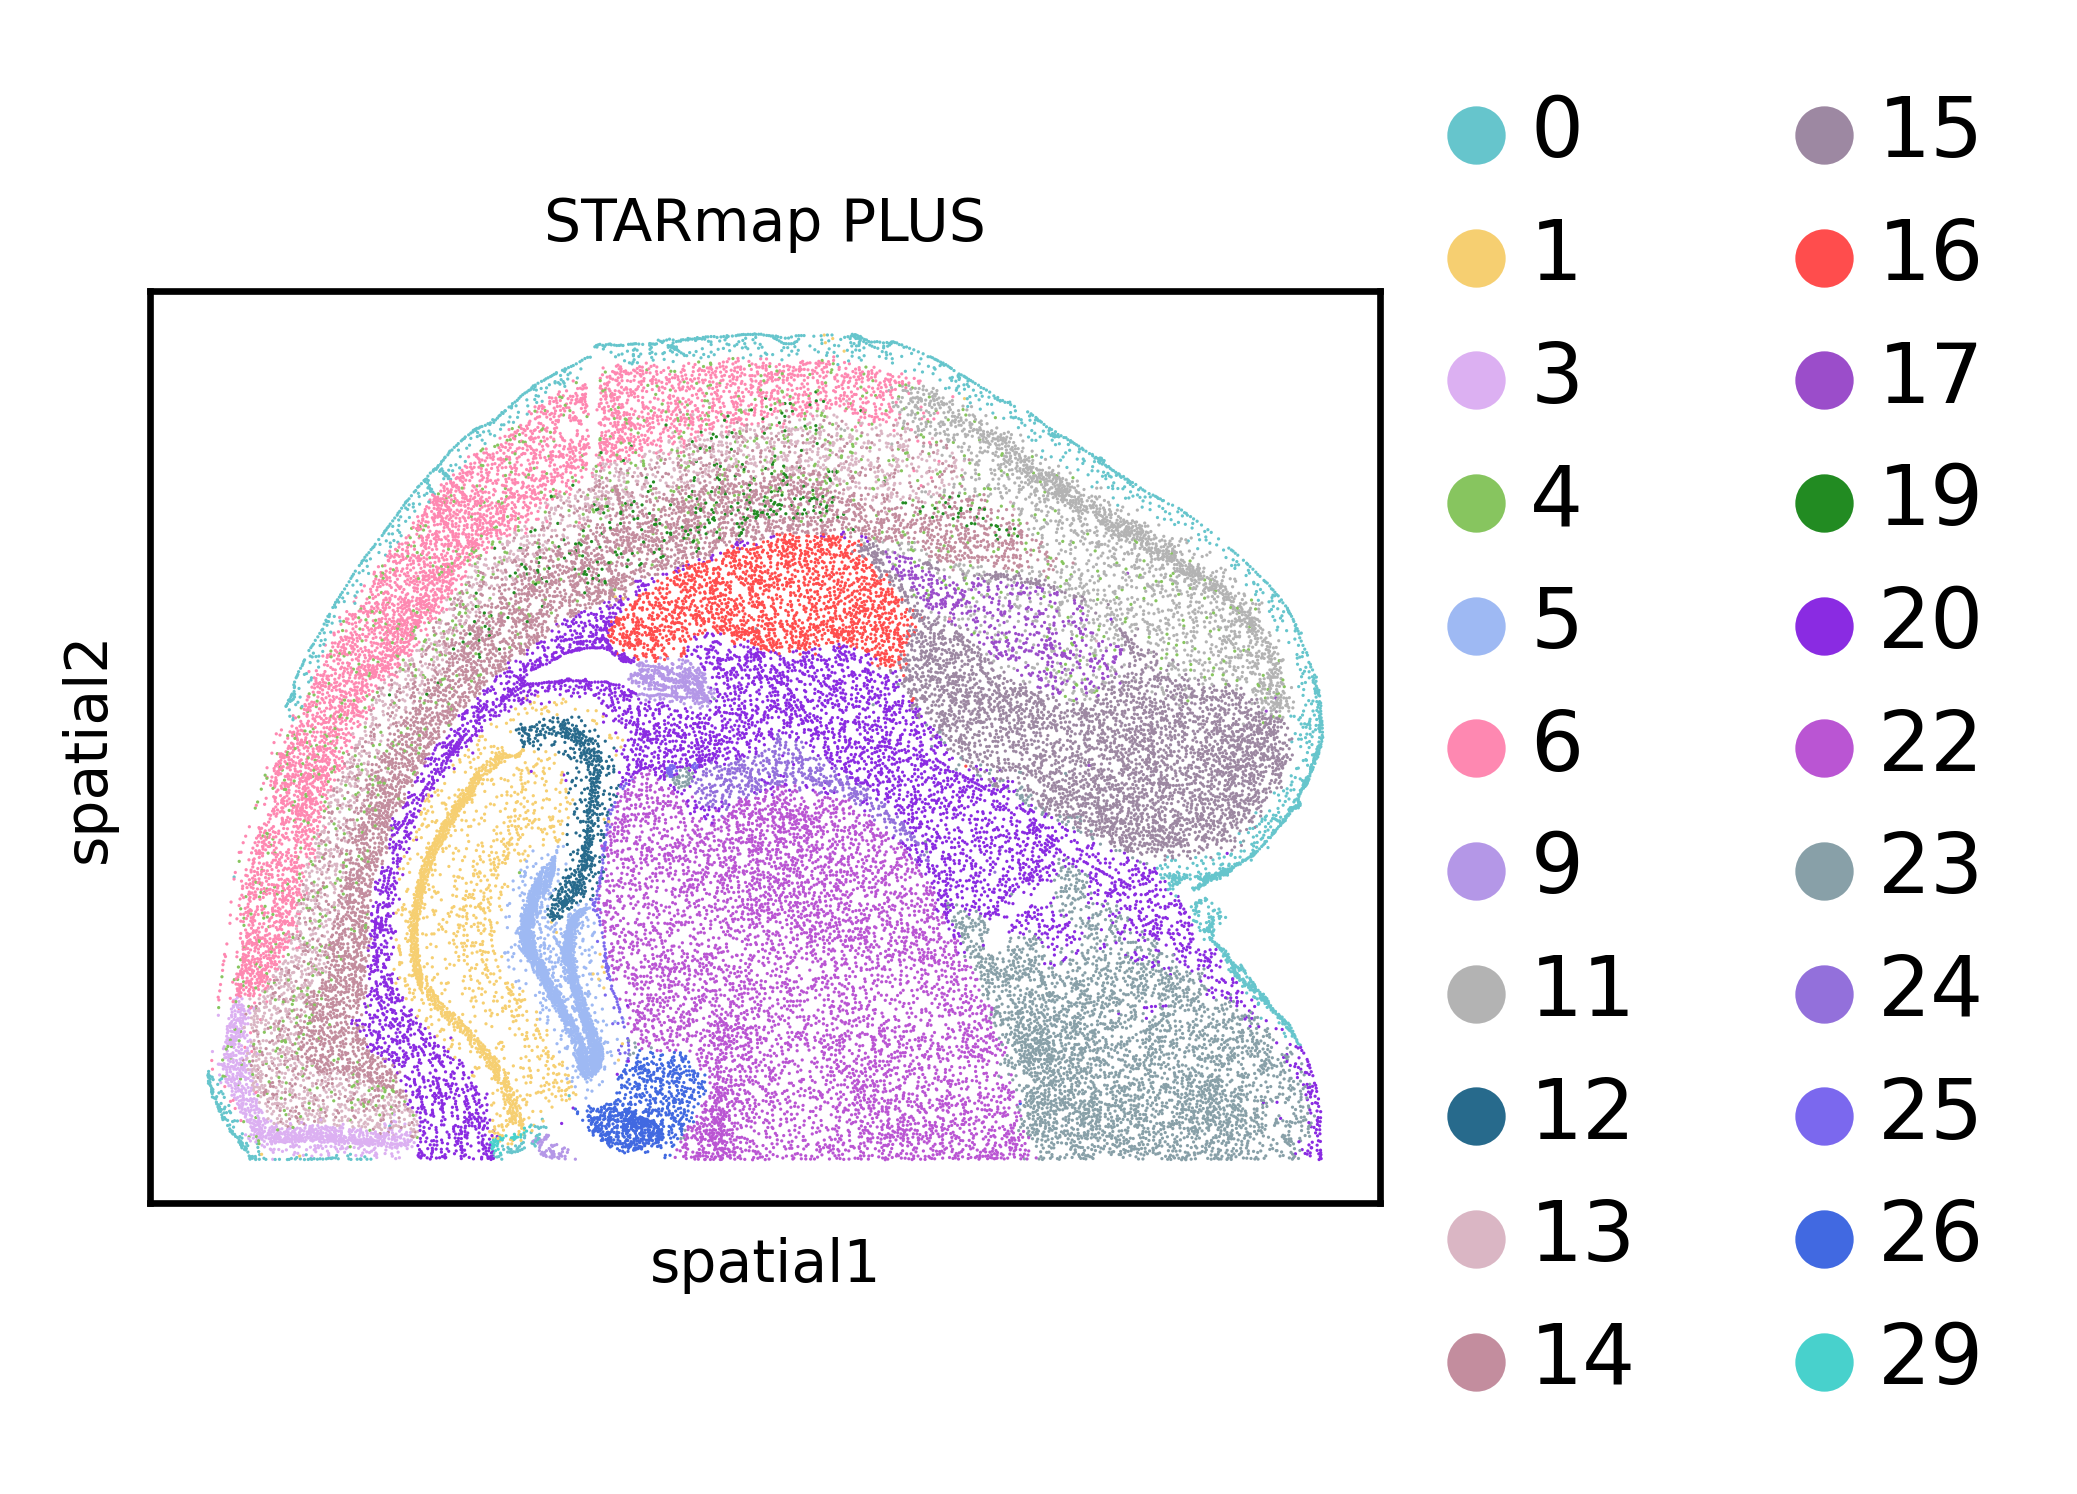

In [40]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [41]:
# Compute average cosine similarity of embeddings
X = adata.obsm[emb_key]
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

cos_sim_result = pd.DataFrame([{
    "emb_key": emb_key,
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

X_cellcharter average cosine similarity: 0.0012638741172850132
Saved → /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/cellcharter/mmb0-1b_smb1-1b_1p_X_cellcharter_avg_cosine_similarity.csv


In [42]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.7071
ARI (Sub_molecular_tissue_region): 0.4296
NMI (ccf_region_name): 0.5893
ARI (ccf_region_name): 0.2198


In [43]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[emb_key], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[emb_key],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, emb_key, batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_batch_integration_metrics.csv",
    index=False
)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


iLISI: 0.0201
ASW batch: 0.0201
MMD: 0.0260


In [44]:
# --- Config -----------------------------------------------------------
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{emb_key}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{emb_key}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.3  (18 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6785  ARI=0.3554
  ccf_region_name                           NMI=0.5738  ARI=0.1727

── Resolution 0.4  (19 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6992  ARI=0.3829
  ccf_region_name                           NMI=0.5743  ARI=0.1704

── Resolution 0.5  (25 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7009  ARI=0.3866
  ccf_region_name                           NMI=0.5779  ARI=0.1827

── Resolution 0.6  (27 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7093  ARI=0.4299
  ccf_region_name                           NMI=0.5875  ARI=0.2145

── Resolution 0.7  (30 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7071  ARI=0.4296
  ccf_region_name                           NMI=0.5893  ARI=0.2198

── Resolution 0.8  (35 clusters) ──
  Sub_molecular_tissue_region               NMI=0.7155  ARI=0.4446
  ccf_region_name                        